# Continuous Forward Curves for SOFR, €STR and EURIBOR: Bootstraps, Nelson–Siegel–Svensson, Splines, Gaussian Processes and Neural Networks

A swap curve is quoted at a dozen tenors, but every trading and risk system needs a forward rate for every date in between. How the gaps are filled decides whether FRAs make sense, whether the risk of a bump lands in the right bucket, and whether the curve jumps when one quote moves. This notebook builds daily curves from real trades and compares nine ways of filling the gaps, judged against prices the market actually traded.

**What it does.** It builds daily forward curves from **real swap trades** reported to the CFTC: SOFR OIS, €STR OIS and EURIBOR-6M swaps discounted on €STR. It then compares nine ways of turning a handful of quotes into a continuous curve:

- four **bootstraps** (QuantLib: linear zero, flat forward, natural cubic zero, Hagan–West monotone convex);
- two **parametric** fits (Nelson–Siegel and Svensson);
- a **penalised forward spline**;
- a **Gaussian-process** (kernel) curve;
- a **neural-network** forward curve fitted directly to swap prices.

**The benchmark is the market itself.** Every method is judged on how well it reprices **forward-starting swaps traded the same day**, which were *not* used to build the curve. It is also judged on leave-one-tenor-out errors, forward smoothness, day-to-day stability and how *local* its hedge ratios are.

**Data.** The DTCC public swap data repository (CFTC cumulative rates reports, ten business days), FRED (SOFR fixing) and the ECB (€STR fixing, EURIBOR 6M).

**Methods.** QuantLib piecewise bootstrapping, Nelson–Siegel(–Svensson), penalised splines, kernel / Gaussian-process regression, and neural networks in PyTorch with a differentiable swap pricer, all tested by repricing forward-start swaps out of sample.

## 1. Why the interpolation method matters

A swap curve is quoted at a few tenors (1M … 50Y), but a trading or risk system needs discount factors and **forward rates at every date**:
- floating cash flows;
- FRAs and forward-starting swaps;
- collateral discounting;
- every hedge ratio.

The choice of interpolation decides what happens *between* the quotes. Hagan and West (2006) list the criteria a desk cares about:
1. **Exact fit** of the input instruments, so the curve reprices what the desk trades;
2. **Plausible, continuous forwards**, without saw-tooth artefacts that make FRAs nonsensical;
3. **Locality**: bumping one quote should move forwards only near that tenor, so the risk lands in the right bucket;
4. **Stability**: small quote changes should not make the forwards jump.

There is a tension:
- Bootstraps fit exactly, but with crude interpolation they produce jagged forwards. Linear zero rates give a forward curve with kinks at every node, and flat forwards give a step function.
- Smooth global methods (splines, NS/NSS) give beautiful forwards but fit inexactly and spread a bump everywhere.
- **Monotone convex** was designed to sit in between. ML methods (GP and NN) are a modern way to trade fit against smoothness.

Since 2021–2023 SOFR replaced USD LIBOR, and €STR is the euro risk-free rate. EURIBOR survives as a term rate, so a euro desk builds a **dual curve**: €STR for discounting and a EURIBOR-6M projection curve.

## 2. Setup

In [1]:
# --- macOS safety switch (must run before any scientific import)
# Several libraries (PyTorch, LightGBM, scikit-learn, NumPy builds) ship their
# own OpenMP runtime.
# On Apple Silicon two copies in one process can make Jupyter report "the
# kernel crashed".
import os

os.environ.setdefault("KMP_DUPLICATE_LIB_OK", "TRUE")


# --- Standard library
import datetime as dt
import io
import re
import time
import warnings
from pathlib import Path

# --- Third-party
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import plotly.graph_objects as go
import requests
from dotenv import find_dotenv, load_dotenv
from fredapi import Fred
from plotly.subplots import make_subplots
import zipfile
import QuantLib as ql
import torch

warnings.filterwarnings("ignore", category=FutureWarning)
pd.set_option("display.float_format", lambda v: f"{v:,.2f}")

PROJECT_DIR = Path.cwd()
DATA_DIR, OUT_DIR = PROJECT_DIR / "data", PROJECT_DIR / "outputs"
DATA_DIR.mkdir(exist_ok=True)
OUT_DIR.mkdir(exist_ok=True)

load_dotenv(find_dotenv(usecwd=True))
FRED_API_KEY = os.getenv("FRED_API_KEY", "").strip()
if not FRED_API_KEY:
    raise RuntimeError(
        "FRED_API_KEY not found. Create the .env file at the repo root (see"
        " .env.example)."
    )
fred = Fred(api_key=FRED_API_KEY)
BROWSER_HEADERS = {
    "User-Agent": (
        "Mozilla/5.0 (Macintosh; Intel Mac OS X 10_15_7) Chrome/130.0"
        " Safari/537.36"
    )
}

SEED = 41
torch.manual_seed(SEED)
torch.set_default_dtype(torch.float64)
DTCC_URL = "https://kgc0418-tdw-data-0.s3.amazonaws.com/cftc/eod/CFTC_CUMULATIVE_RATES_{d:%Y_%m_%d}.zip"
ECB = "https://data-api.ecb.europa.eu/service/data/{}?format=csvdata&startPeriod=2026-01-01"
# business days of trade reports
N_DAYS = 10
GRID_M = [
    1,
    2,
    3,
    4,
    5,
    6,
    9,
    12,
    18,
    24,
    36,
    48,
    60,
    72,
    84,
    96,
    108,
    120,
    144,
    180,
    240,
    300,
    360,
    480,
    600,
]
# trades needed for a tenor quote on a day
MIN_TRADES = 2
# tenors removed one at a time in the leave-one-out test
LOO_TENORS = [24, 36, 60, 84, 120, 180, 240, 300]
T_MAX = 52.0  # curve horizon (years)

print(
    f"QuantLib {ql.__version__} · torch {torch.__version__} · run on"
    f" {dt.date.today():%Y-%m-%d}"
)

QuantLib 1.44 · torch 2.14.1+cu130 · run on 2026-10-20


In [2]:
# --- Caching helper: every download is stored in data/ and reused for 12 hours
def cached(name, fetch, max_age_hours=12):
    path = DATA_DIR / f"{name}.parquet"
    if (
        path.exists()
        and (time.time() - path.stat().st_mtime) / 3600 < max_age_hours
    ):
        return pd.read_parquet(path)
    try:
        frame = fetch()
        frame.to_parquet(path)
        return frame
    except Exception as err:
        if path.exists():
            print(
                f"⚠️  {name}: download failed ({type(err).__name__}); using"
                " cached copy"
            )
            return pd.read_parquet(path)
        raise


# --- Chart style
PALETTE = [
    "#2a78d6",
    "#eb6834",
    "#1baf7a",
    "#eda100",
    "#e87ba4",
    "#008300",
    "#6250d6",
    "#e34948",
]
INK, INK_2, GRID, SURFACE = "#0b0b0b", "#52514e", "#e4e3df", "#fcfcfb"
STATUS = {"green": "#1baf7a", "amber": "#eda100", "red": "#e34948"}
plt.rcParams.update({
    "figure.facecolor": SURFACE,
    "axes.facecolor": SURFACE,
    "savefig.facecolor": SURFACE,
    "axes.edgecolor": GRID,
    "axes.labelcolor": INK_2,
    "axes.titlecolor": INK,
    "axes.titlesize": 12,
    "axes.titleweight": "bold",
    "axes.titlelocation": "left",
    "axes.grid": True,
    "grid.color": GRID,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "xtick.color": INK_2,
    "ytick.color": INK_2,
    "legend.frameon": False,
    "lines.linewidth": 2.0,
    "font.size": 10,
    "figure.dpi": 110,
    "axes.axisbelow": True,
})


def save_fig(fig, name):
    fig.savefig(OUT_DIR / f"{name}.png", dpi=150, bbox_inches="tight")


def save_dashboard(dash, name):
    """
    Interactive HTML always; static PNG (for GitHub) when kaleido can find
    Chrome.
    """
    dash.write_html(OUT_DIR / f"{name}.html", include_plotlyjs="cdn")
    try:
        dash.write_image(OUT_DIR / f"{name}.png", scale=2)
        print(f"Dashboard saved: outputs/{name}.html and .png")
    except Exception as err:
        print(
            f"Dashboard saved as HTML; PNG skipped ({type(err).__name__}). Run"
            " `plotly_get_chrome` once."
        )


def tenor_label(t):
    return f"{int(round(t * 12))}M" if t < 1 else f"{t:g}Y"

## 3. Swap trades from the DTCC public repository

Under CFTC Part 43 every swap with a US person is publicly reported within minutes, with fixed rate, effective and expiry dates, notional (capped) and floating index. The cumulative end-of-day rates reports of the last ten business days are downloaded, keeping:
- **SOFR OIS**: USD overnight-index swaps on SOFR;
- **€STR OIS**: EUR overnight-index swaps on €STR;
- **EURIBOR 6M swaps**: EUR fixed vs EURIBOR with a 6-month reset, the standard euro swap above two years.

**Cleaning:**
- keep new trades (`NEWT`) that are not part of a package (packages such as curve spreads can be priced off-market) and do not have non-standard terms;
- drop trades whose fixed rate is an exact multiple of 12.5 bp. These are standardised-coupon (MAC) swaps that start on IMM dates and settle the difference to par with an upfront fee, so their rate is not a par rate;
- a trade is **spot-starting** if it becomes effective within seven days of execution, and its tenor is snapped to the standard grid;
- each day and tenor, outliers more than three median absolute deviations away are removed, and the quote is the notional-weighted median.

Trades starting **one month to two years forward** form the **out-of-sample test set**, in buckets of at least three trades with the same start date and tenor. They are priced off the same day's curve but never used to build it. Buckets that *every* exact bootstrap misses by more than 25 bp are set aside as off-market or mis-reported.

Typical cases are seasoned trades or coupons with an upfront fee that slipped through the filters.

In [3]:
def fetch_dtcc():
    keep = [
        "Action type",
        "Execution Timestamp",
        "Effective Date",
        "Expiration Date",
        "Package indicator",
        "Non-standardized term indicator",
        "Notional amount-Leg 1",
        "Fixed rate-Leg 1",
        "Fixed rate-Leg 2",
        "UPI FISN",
        "UPI Underlier Name",
        "Floating rate reset frequency period-leg 1",
        "Floating rate reset frequency period-leg 2",
        "Floating rate reset frequency period multiplier-leg 1",
        "Floating rate reset frequency period multiplier-leg 2",
    ]
    out, day = [], dt.date.today()
    while len(out) < N_DAYS:
        day -= dt.timedelta(days=1)
        if day.weekday() >= 5:
            continue
        try:
            r = requests.get(DTCC_URL.format(d=day), timeout=120)
            r.raise_for_status()
        except requests.RequestException:
            continue
        z = zipfile.ZipFile(io.BytesIO(r.content))
        raw = pd.read_csv(z.open(z.namelist()[0]), dtype=str, low_memory=False)
        f, u = raw["UPI FISN"].fillna(""), raw["UPI Underlier Name"].fillna("")
        m = (
            (f.eq("NA/Swap OIS USD") & u.str.contains("SOFR"))
            | (f.eq("NA/Swap OIS EUR") & u.str.contains("EuroSTR"))
            | (f.eq("NA/Swap Fxd Flt EUR") & u.str.contains("EURIBOR"))
        )
        x = raw.loc[m, [c for c in keep if c in raw.columns]].copy()
        x["file_date"] = day.isoformat()
        out.append(x)
    return pd.concat(out, ignore_index=True)


raw = cached("dtcc_swaps", fetch_dtcc, max_age_hours=24 * 3)
t = raw.copy()
t["trade"] = pd.to_datetime(t["Execution Timestamp"].str[:10])
t["eff"] = pd.to_datetime(t["Effective Date"], errors="coerce")
t["exp"] = pd.to_datetime(t["Expiration Date"], errors="coerce")
t["rate"] = pd.to_numeric(t["Fixed rate-Leg 1"], errors="coerce").fillna(
    pd.to_numeric(t["Fixed rate-Leg 2"], errors="coerce")
)
t["notional"] = (
    pd.to_numeric(
        t["Notional amount-Leg 1"].str.replace(r"[^0-9.]", "", regex=True),
        errors="coerce",
    )
    .fillna(1e6)
    .clip(1e5, 1e10)
)
reset = t["Floating rate reset frequency period multiplier-leg 1"].fillna(
    t["Floating rate reset frequency period multiplier-leg 2"]
).fillna("") + t["Floating rate reset frequency period-leg 1"].fillna(
    t["Floating rate reset frequency period-leg 2"]
).fillna(
    ""
)
t["curve"] = np.select(
    [t["UPI FISN"].str.contains("USD"), t["UPI FISN"].str.contains("OIS")],
    ["SOFR", "ESTR"],
    "EURIBOR6M",
)
# standard 12.5/25 bp coupons (MAC swaps) trade with an upfront fee
mac = np.abs(t["rate"] * 800 - np.round(t["rate"] * 800)) < 1e-6
t = t[
    (t["Action type"] == "NEWT")
    & (t["Package indicator"] != "TRUE")
    & (t["Non-standardized term indicator"] != "TRUE")
    & ~mac
    & t["rate"].between(-0.01, 0.10)
    & ((t["curve"] != "EURIBOR6M") | (reset == "6MNTH"))
].copy()
# trades executed on the report date
t = t[t["trade"].dt.date.astype(str) == t["file_date"]]
t["fwd_days"] = (t["eff"] - t["trade"]).dt.days
t["len_m"] = (t["exp"] - t["eff"]).dt.days / 30.4375
grid = np.array(GRID_M)
near = np.abs(t["len_m"].to_numpy()[:, None] - grid[None, :])
t["tenor_m"] = grid[near.argmin(1)]
# about a week at the short end, 2-3 weeks at the long end
tol = np.maximum(0.25, 0.012 * t["tenor_m"])
t = t[near.min(1) <= tol]


def robust_quote(g):
    med = g["rate"].median()
    mad = (g["rate"] - med).abs().median()
    g = g[(g["rate"] - med).abs() <= max(3 * 1.4826 * mad, 1e-4)]
    o = np.argsort(g["rate"].to_numpy())
    w = g["notional"].to_numpy()[o].cumsum()
    return pd.Series({
        "rate": g["rate"].to_numpy()[o][np.searchsorted(w, w[-1] / 2)],
        "trades": len(g),
    })


spot = (
    t[t["fwd_days"].between(0, 7)]
    .groupby(["curve", "file_date", "tenor_m"])
    .apply(robust_quote, include_groups=False)
    .reset_index()
)
spot = spot[spot["trades"] >= MIN_TRADES]
fwd = t[t["fwd_days"].between(28, 760) & (t["tenor_m"] >= 12)].copy()
fwd["eff_d"] = fwd["eff"].dt.date
fwd = (
    fwd.groupby(["curve", "file_date", "eff_d", "tenor_m"])
    .apply(robust_quote, include_groups=False)
    .reset_index()
)
fwd = fwd[fwd["trades"] >= 3]
DAYS = sorted(spot["file_date"].unique())
print(
    f"{len(t):,} clean trades · {len(spot):,} daily spot quotes ·"
    f" {len(fwd):,} forward-start test buckets · days {DAYS[0]} → {DAYS[-1]}"
)
spot.groupby(["curve", "file_date"])["tenor_m"].count().unstack(
    0
).describe().loc[["min", "50%", "max"]].rename(index={"50%": "median"}).astype(
    int
)

18,983 clean trades · 486 daily spot quotes · 305 forward-start test buckets · days 2026-10-06 → 2026-10-19


curve,ESTR,EURIBOR6M,SOFR
min,11,10,23
median,14,13,23
max,19,16,23


## 4. Fixings and the instruments' cash-flow schedules

The overnight end of each OIS curve is anchored with the latest fixing:
- **SOFR** from FRED;
- **€STR** from the ECB.

The EURIBOR-6M curve is anchored with the 6-month EURIBOR. The ECB publishes it only as a monthly average, so the last monthly value is used as a 6-month deposit. This is a documented approximation: in practice desks use the daily fixing or FRAs.

**Schedules.** Every instrument's schedule is generated with QuantLib calendars and conventions:
- SOFR: US government-bond calendar;
- €STR and EURIBOR: TARGET;
- two-day spot lag, modified following;
- OIS: annual payments, ACT/360;
- EURIBOR swaps: annual 30/360 fixed against semi-annual ACT/360 floating.

A **differentiable pricer** then values each instrument from any discount function P(t):
- OIS: par = (P(s) − P(e)) / Σ τᵢ P(tᵢ);
- EURIBOR swap: par = Σ τⱼ Fⱼ P_€STR(tⱼ) / Σ τᵢ P_€STR(tᵢ), with Fⱼ the EURIBOR forward from the projection curve.

The same pricer serves every method, from bootstraps to neural networks, so they are compared on identical terms.

In [4]:
fixings = {}
sofr_fix = fred.get_series("SOFR").dropna() / 100
estr = pd.read_csv(
    io.StringIO(
        requests.get(ECB.format("EST/B.EU000A2X2A25.WT"), timeout=60).text
    )
)
estr_fix = pd.Series(
    estr["OBS_VALUE"].to_numpy() / 100,
    index=pd.to_datetime(estr["TIME_PERIOD"]),
)
e6 = pd.read_csv(
    io.StringIO(
        requests.get(
            ECB.format("FM/M.U2.EUR.RT.MM.EURIBOR6MD_.HSTA"), timeout=60
        ).text
    )
)
eur6m_fix = float(e6["OBS_VALUE"].iloc[-1]) / 100
CONV = {
    "SOFR": dict(
        cal=ql.UnitedStates(ql.UnitedStates.GovernmentBond), index=ql.Sofr()
    ),
    "ESTR": dict(cal=ql.TARGET(), index=ql.Estr()),
    "EURIBOR6M": dict(cal=ql.TARGET(), index=ql.Euribor6M()),
}
A360, A365, T360 = (
    ql.Actual360(),
    ql.Actual365Fixed(),
    ql.Thirty360(ql.Thirty360.BondBasis),
)
qd = lambda d: ql.Date(d.day, d.month, d.year)


def make_instrument(curve, day, tenor_m, start=None):
    """
    Cash-flow skeleton of a par instrument: times (ACT/365F from the trade
    date) and accrual fractions.
    """
    c = CONV[curve]["cal"]
    d0 = qd(day)
    s = (
        c.advance(d0, 2, ql.Days)
        if start is None
        else c.adjust(qd(start), ql.ModifiedFollowing)
    )
    e = c.advance(s, ql.Period(int(tenor_m), ql.Months), ql.ModifiedFollowing)
    tt = lambda d: A365.yearFraction(d0, d)
    if curve in ("SOFR", "ESTR"):
        sch = list(
            ql.Schedule(
                s,
                e,
                ql.Period(ql.Annual),
                c,
                ql.ModifiedFollowing,
                ql.ModifiedFollowing,
                ql.DateGeneration.Backward,
                False,
            )
        )
        return dict(
            kind="ois",
            s=tt(s),
            e=tt(e),
            t=np.array([tt(d) for d in sch[1:]]),
            tau=np.array(
                [A360.yearFraction(a, b) for a, b in zip(sch[:-1], sch[1:])]
            ),
        )
    fx = list(
        ql.Schedule(
            s,
            e,
            ql.Period(ql.Annual),
            c,
            ql.ModifiedFollowing,
            ql.ModifiedFollowing,
            ql.DateGeneration.Forward,
            False,
        )
    )
    fl = list(
        ql.Schedule(
            s,
            e,
            ql.Period(ql.Semiannual),
            c,
            ql.ModifiedFollowing,
            ql.ModifiedFollowing,
            ql.DateGeneration.Forward,
            False,
        )
    )
    return dict(
        kind="ibor",
        t=np.array([tt(d) for d in fx[1:]]),
        tau=np.array(
            [T360.yearFraction(a, b) for a, b in zip(fx[:-1], fx[1:])]
        ),
        fs=np.array([tt(d) for d in fl[:-1]]),
        fe=np.array([tt(d) for d in fl[1:]]),
        ftau=np.array(
            [A360.yearFraction(a, b) for a, b in zip(fl[:-1], fl[1:])]
        ),
    )


def fixing_instrument(curve, day):
    c, d0 = CONV[curve]["cal"], qd(day)
    if curve == "EURIBOR6M":
        s = c.advance(d0, 2, ql.Days)
        e = c.advance(s, ql.Period(6, ql.Months), ql.ModifiedFollowing)
        return (
            dict(
                kind="depo",
                s=A365.yearFraction(d0, s),
                e=A365.yearFraction(d0, e),
                tau=A360.yearFraction(s, e),
            ),
            eur6m_fix,
        )
    e = c.advance(d0, 1, ql.Days)
    fx = sofr_fix if curve == "SOFR" else estr_fix
    return dict(
        kind="depo",
        s=0.0,
        e=A365.yearFraction(d0, e),
        tau=A360.yearFraction(d0, e),
    ), float(fx[: pd.Timestamp(day)].iloc[-1])


def par_rate(ins, P, Pd=None):
    """
    Par rate of an instrument from discount functions P (curve) and Pd
    (discounting, EURIBOR only). Works with numpy or torch.
    """
    if ins["kind"] == "depo":
        return (P(ins["s"]) / P(ins["e"]) - 1) / ins["tau"]
    if ins["kind"] == "ois":
        pt = P(ins["t"])
        tau = (
            torch.as_tensor(ins["tau"]) if torch.is_tensor(pt) else ins["tau"]
        )
        return (P(ins["s"]) - P(ins["e"])) / (tau * pt).sum()
    pfe = P(ins["fe"])
    cv_ = (
        (lambda x: torch.as_tensor(x))
        if torch.is_tensor(pfe)
        else (lambda x: x)
    )
    F = (P(ins["fs"]) / pfe - 1) / cv_(ins["ftau"])
    return (cv_(ins["ftau"]) * F * cv_(Pd(ins["fe"]))).sum() / (
        cv_(ins["tau"]) * cv_(Pd(ins["t"]))
    ).sum()


BOOK = {}
for (cv, day), g in spot.groupby(["curve", "file_date"]):
    dday = dt.date.fromisoformat(day)
    fi, fr = fixing_instrument(cv, dday)
    ins = [fi] + [make_instrument(cv, dday, m) for m in g["tenor_m"]]
    # the 6M deposit replaces any 6M swap quote
    if cv == "EURIBOR6M":
        keep = [0] + [i + 1 for i, m in enumerate(g["tenor_m"]) if m >= 12]
        ins = [ins[i] for i in keep]
        tenors = [6] + [m for m in g["tenor_m"] if m >= 12]
        rates = [fr] + [r for m, r in zip(g["tenor_m"], g["rate"]) if m >= 12]
    else:
        tenors, rates = [0] + list(g["tenor_m"]), [fr] + list(g["rate"])
    ft = fwd[(fwd["curve"] == cv) & (fwd["file_date"] == day)]
    BOOK[(cv, day)] = dict(
        ins=ins,
        tenor_m=np.array(tenors),
        rate=np.array(rates),
        day=dday,
        fwd_ins=[
            make_instrument(cv, dday, m, start=s)
            for s, m in zip(ft["eff_d"], ft["tenor_m"])
        ],
        fwd_rate=ft["rate"].to_numpy(),
        fwd_meta=ft[["eff_d", "tenor_m", "trades"]].reset_index(drop=True),
    )
print(
    f"SOFR {sofr_fix.iloc[-1]:.2%} · €STR {estr_fix.iloc[-1]:.3%} · EURIBOR 6M"
    f" (last monthly average) {eur6m_fix:.3%} · {len(BOOK)} curve-days"
)

SOFR 3.87% · €STR 2.441% · EURIBOR 6M (last monthly average) 2.922% · 29 curve-days


## 5. The nine curve methods

| family | method | what is interpolated | exact fit? |
|---|---|---|---|
| bootstrap | linear zero | zero rates, piecewise linear | yes |
| bootstrap | flat forward | log discount factors, linear (forwards are step functions) | yes |
| bootstrap | natural cubic zero | zero rates, global natural cubic spline | yes |
| bootstrap | **monotone convex** (Hagan–West) | forwards, local quadratic with positivity and monotonicity | yes |
| parametric | Nelson–Siegel | 4 parameters | no |
| parametric | Svensson | 6 parameters | no |
| smoothing | penalised forward spline | 80 forward knots, roughness penalty λ·Σ(Δ²f)² | nearly |
| ML | Gaussian process (kernel) | zero rate = NS mean + RBF kernel expansion with a GP prior penalty | nearly |
| ML | neural network | instantaneous forward = MLP(log t), integrated to discount factors | nearly |

Bootstraps use QuantLib's `Piecewise…` curves with `OISRateHelper`, `DepositRateHelper` and `SwapRateHelper`. The EURIBOR helpers use exogenous €STR discounting, so the curve is a true dual curve.

The other five are fitted in **PyTorch**: the swap pricer above is differentiable, so parameters are optimised directly on par-rate errors in basis points with L-BFGS.
- **NN and spline forwards:** integrated on a fine time grid to give zero rates.
- **GP weights:** penalised by αᵀKα, the negative log-prior of a Gaussian process with that kernel. Its MAP estimate is the fitted curve.

For EURIBOR, all non-bootstrap methods use the €STR monotone-convex curve of the same day for discounting.

In [5]:
QL_METHODS = {
    "linear zero": ql.PiecewiseLinearZero,
    "flat forward": ql.PiecewiseLogLinearDiscount,
    "natural cubic zero": ql.PiecewiseNaturalCubicZero,
    "monotone convex": ql.PiecewiseConvexMonotoneForward,
}
TORCH_METHODS = [
    "Nelson–Siegel",
    "Svensson",
    "penalised spline",
    "Gaussian process",
    "neural network",
]
METHODS = list(QL_METHODS) + TORCH_METHODS


def ql_curve(method, cv, day, rates, tenors, disc=None):
    d0 = qd(day)
    ql.Settings.instance().evaluationDate = d0
    c = CONV[cv]
    helpers = []
    for m, r in zip(tenors, rates):
        q = ql.QuoteHandle(ql.SimpleQuote(float(r)))
        if cv == "EURIBOR6M":
            if m == 6:
                helpers.append(ql.DepositRateHelper(q, ql.Euribor6M()))
            else:
                helpers.append(
                    ql.SwapRateHelper(
                        q,
                        ql.Period(int(m), ql.Months),
                        c["cal"],
                        ql.Annual,
                        ql.ModifiedFollowing,
                        T360,
                        ql.Euribor6M(),
                        ql.QuoteHandle(),
                        ql.Period(0, ql.Days),
                        disc,
                    )
                )
        elif m == 0:
            helpers.append(
                ql.DepositRateHelper(
                    q,
                    ql.Period(1, ql.Days),
                    0,
                    c["cal"],
                    ql.Following,
                    False,
                    A360,
                )
            )
        else:
            helpers.append(
                ql.OISRateHelper(
                    2, ql.Period(int(m), ql.Months), q, c["index"]
                )
            )
    crv = QL_METHODS[method](d0, helpers, A365)
    crv.enableExtrapolation()
    return crv


def np_discount(crv):
    g = np.concatenate([[0.0], np.geomspace(1 / 365, T_MAX, 1500)])
    lnP = np.log([crv.discount(float(x)) for x in g])
    return lambda x: np.exp(np.interp(np.asarray(x, float), g, lnP))


# fine grid for integrating forwards (one week)
TG = torch.linspace(0, T_MAX, 2601)
KN = torch.tensor(np.concatenate([[0.0], np.geomspace(1 / 12, T_MAX, 79)]))


def interp_t(x, xp, fp):
    x = torch.as_tensor(x, dtype=fp.dtype)
    i = torch.clamp(torch.searchsorted(xp, x) - 1, 0, len(xp) - 2)
    w = (x - xp[i]) / (xp[i + 1] - xp[i])
    return fp[i] + w * (fp[i + 1] - fp[i])


def ns_zero(t, b, tau):
    # avoids 0/0 (and NaN gradients) at t = 0
    x = torch.clamp(t / tau, min=1e-6)
    h1 = (1 - torch.exp(-x)) / x
    return b[0] + b[1] * h1 + b[2] * (h1 - torch.exp(-x))


class TorchCurve:
    """
    A curve whose discount function is a differentiable function of its
    parameters.
    """

    def __init__(self, method, z0):
        self.m = method
        if method in ("Nelson–Siegel", "Svensson"):
            n = 4 if method == "Nelson–Siegel" else 6
            init = [z0, -0.005, 0.0, 1.0] + ([0.0, 1.5] if n == 6 else [])
            self.p = torch.tensor(init, requires_grad=True)
        elif method == "penalised spline":
            self.p = torch.full((len(KN),), z0, requires_grad=True)
        elif method == "Gaussian process":
            self.ctr = torch.log1p(KN[1:])
            self.p = torch.cat([
                torch.tensor([z0, -0.005, 0.0, 0.5]),
                torch.zeros(len(self.ctr)),
            ]).requires_grad_(True)
        else:
            self.net = torch.nn.Sequential(
                torch.nn.Linear(1, 24),
                torch.nn.Tanh(),
                torch.nn.Linear(24, 24),
                torch.nn.Tanh(),
                torch.nn.Linear(24, 1),
            )
            with torch.no_grad():
                self.net[-1].bias.fill_(z0)
                self.net[-1].weight.mul_(0.01)
            self.p = None

    def params(self):
        return list(self.net.parameters()) if self.p is None else [self.p]

    def forward_grid(self):
        if self.m == "penalised spline":
            return interp_t(TG, KN, self.p)
        return self.net(torch.log1p(TG)[:, None]).squeeze(1)

    def zero(self, t):
        t = t if torch.is_tensor(t) else torch.as_tensor(np.asarray(t, float))
        if self.m == "Nelson–Siegel":
            return ns_zero(
                t, self.p[:3], torch.nn.functional.softplus(self.p[3]) + 0.05
            )
        if self.m == "Svensson":
            tau1, tau2 = (
                torch.nn.functional.softplus(self.p[3]) + 0.05,
                torch.nn.functional.softplus(self.p[5]) + 0.5,
            )
            x2 = torch.clamp(t / tau2, min=1e-6)
            h2 = (1 - torch.exp(-x2)) / x2 - torch.exp(-x2)
            return ns_zero(t, self.p[:3], tau1) + self.p[4] * h2
        if self.m == "Gaussian process":
            mean = ns_zero(
                t, self.p[:3], torch.nn.functional.softplus(self.p[3]) + 0.05
            )
            k = (
                torch.exp(
                    -0.5
                    * ((torch.log1p(t)[:, None] - self.ctr[None, :]) / 0.35)
                    ** 2
                )
                if t.ndim
                else torch.exp(
                    -0.5 * ((torch.log1p(t) - self.ctr) / 0.35) ** 2
                )
            )
            return mean + k @ self.p[4:]
        f = self.forward_grid()
        cum = torch.cat([
            torch.zeros(1),
            torch.cumsum((f[1:] + f[:-1]) / 2 * (TG[1:] - TG[:-1]), 0),
        ])
        return (
            interp_t(t, TG, cum) / torch.clamp(t, min=1e-6)
            if t.ndim
            else interp_t(t[None], TG, cum)[0] / max(float(t), 1e-6)
        )

    def P(self, t):
        t_ = t if torch.is_tensor(t) else torch.as_tensor(np.asarray(t, float))
        shp = t_.shape
        flat = t_.reshape(-1)
        return torch.exp(-self.zero(flat) * flat).reshape(shp)

    def penalty(self):
        if self.m == "penalised spline":
            return (
                2e5
                * ((self.p[2:] - 2 * self.p[1:-1] + self.p[:-2]) ** 2).sum()
            )
        if self.m == "Gaussian process":
            K = torch.exp(
                -0.5 * ((self.ctr[:, None] - self.ctr[None, :]) / 0.35) ** 2
            )
            return 2e3 * self.p[4:] @ K @ self.p[4:]
        if self.m == "neural network":
            f = self.forward_grid()[::10]
            return 2e5 * ((f[2:] - 2 * f[1:-1] + f[:-2]) ** 2).sum()
        return torch.tensor(0.0)


class VecBook:
    """
    All instruments of a curve-day packed into padded tensors, so one discount-
    function call prices them all.
    """

    def __init__(self, ins, disc_np=None):
        self.depo = [i for i, x in enumerate(ins) if x["kind"] == "depo"]
        self.swp = [i for i, x in enumerate(ins) if x["kind"] != "depo"]
        self.n = len(ins)
        pad = lambda arrs: torch.tensor(
            np.array(
                [np.pad(a, (0, max(map(len, arrs)) - len(a))) for a in arrs]
            )
        )
        d = [ins[i] for i in self.depo]
        self.ds, self.de, self.dtau = (
            torch.tensor([x[k] for x in d]) for k in ("s", "e", "tau")
        )
        w = [ins[i] for i in self.swp]
        self.kind = w[0]["kind"] if w else "ois"
        self.T, self.TAU = pad([x["t"] for x in w]), pad([x["tau"] for x in w])
        if self.kind == "ois":
            self.S, self.E = torch.tensor([x["s"] for x in w]), torch.tensor(
                [x["e"] for x in w]
            )
        else:
            self.FS, self.FE, self.FTAU = (
                pad([x["fs"] for x in w]),
                pad([x["fe"] for x in w]),
                pad([x["ftau"] for x in w]),
            )
            self.PD_T = torch.tensor(disc_np(self.T.numpy())) * (self.TAU > 0)
            self.PD_FE = torch.tensor(disc_np(self.FE.numpy())) * (
                self.FTAU > 0
            )

    def par(self, P):
        out = torch.zeros(self.n)
        out[self.depo] = (P(self.ds) / P(self.de) - 1) / self.dtau
        if self.kind == "ois":
            out[self.swp] = (P(self.S) - P(self.E)) / (
                self.TAU * P(self.T)
            ).sum(1)
        else:
            F = (P(self.FS) / P(self.FE) - 1) / torch.where(
                self.FTAU > 0, self.FTAU, 1.0
            )
            out[self.swp] = (self.FTAU * F * self.PD_FE).sum(1) / (
                self.TAU * self.PD_T
            ).sum(1)
        return out


def torch_fit(method, book, disc_np=None, drop=None, steps=150):
    idx = [i for i in range(len(book["ins"])) if i != drop]
    vb = VecBook([book["ins"][i] for i in idx], disc_np)
    mkt = torch.tensor(book["rate"][idx])
    w = torch.tensor(
        [3.0 if book["ins"][i]["kind"] == "depo" else 1.0 for i in idx]
    )
    tc = TorchCurve(method, float(np.median(book["rate"])))
    loss_fn = (
        lambda: (w * ((vb.par(tc.P) - mkt) * 1e4) ** 2).mean() + tc.penalty()
    )
    if method == "neural network":
        opt = torch.optim.Adam(tc.params(), lr=0.01)
        for _ in range(400):
            opt.zero_grad()
            loss = loss_fn()
            loss.backward()
            opt.step()
    opt = torch.optim.LBFGS(
        tc.params(), lr=0.5, max_iter=steps, line_search_fn="strong_wolfe"
    )

    def closure():
        opt.zero_grad()
        loss = loss_fn()
        loss.backward()
        return loss

    opt.step(closure)
    g = np.concatenate([[0.0], np.geomspace(1 / 365, T_MAX, 1500)])
    with torch.no_grad():
        lnP = np.log(tc.P(g).numpy())
    return lambda x: np.exp(np.interp(np.asarray(x, float), g, lnP))


def build(method, cv, day, drop=None, bump=None):
    """
    Discount function of one method for one curve-day (optionally dropping or
    bumping one quote).
    """
    b = BOOK[(cv, day)]
    rates = b["rate"].copy()
    if bump is not None:
        rates[bump] += 1e-4
    disc_np, disc_h = None, None
    if cv == "EURIBOR6M":
        ec = ql_curve(
            "monotone convex",
            "ESTR",
            b["day"],
            BOOK[("ESTR", day)]["rate"],
            BOOK[("ESTR", day)]["tenor_m"],
        )
        disc_np, disc_h = np_discount(ec), ql.YieldTermStructureHandle(ec)
    if method in QL_METHODS:
        keep = [i for i in range(len(rates)) if i != drop]
        try:
            return (
                np_discount(
                    ql_curve(
                        method,
                        cv,
                        b["day"],
                        rates[keep],
                        b["tenor_m"][keep],
                        disc_h,
                    )
                ),
                disc_np,
            )
        # bootstrap failed (e.g. long gap after dropping a tenor)
        except RuntimeError:
            return None, disc_np
    bb = dict(b, rate=rates)
    return torch_fit(method, bb, disc_np, drop=drop), disc_np


def reprice(P, Pd, ins_list):
    return np.array([float(par_rate(i, P, Pd)) for i in ins_list])


day0 = DAYS[-1]
P_chk, Pd_chk = build("monotone convex", "SOFR", day0)
err_chk = (
    reprice(P_chk, Pd_chk, BOOK[("SOFR", day0)]["ins"])
    - BOOK[("SOFR", day0)]["rate"]
) * 1e4
print(
    "Pricer check: QuantLib monotone-convex SOFR curve repriced by the numpy"
    f" pricer, max error {np.abs(err_chk).max():.3f} bp"
)

Pricer check: QuantLib monotone-convex SOFR curve repriced by the numpy pricer, max error 0.054 bp


## 6. Fitting every method on every day

For each of the ten days and three curves, all nine methods are built. Each is evaluated on:
- **in-sample error**: repricing of the spot quotes used to build it;
- **forward-start error**: repricing of the same day's forward-starting swaps, the market benchmark the curve never saw;
- **forward roughness**: the mean absolute second difference of the 1-month forward curve on a monthly grid out to 30 years, in bp. A saw-tooth curve scores high.

The fits take a few minutes, because the PyTorch methods are optimised 30 times each.

In [6]:
FWD_T = np.arange(1 / 12, 30.001, 1 / 12)


def fwd_curve(P, step=1 / 12):
    return (P(FWD_T) / P(FWD_T + step) - 1) / step


rows, FWDS = [], {}
t0 = time.time()
for (cv, day), b in BOOK.items():
    for m in METHODS:
        P, Pd = build(m, cv, day)
        if P is None:
            continue
        ins_err = (reprice(P, Pd, b["ins"]) - b["rate"]) * 1e4
        fw_err = (
            (reprice(P, Pd, b["fwd_ins"]) - b["fwd_rate"]) * 1e4
            if len(b["fwd_ins"])
            else np.array([])
        )
        f = fwd_curve(P)
        FWDS[(cv, day, m)] = f
        rows.append({
            "curve": cv,
            "day": day,
            "method": m,
            "in-sample RMSE (bp)": np.sqrt(np.mean(ins_err[1:] ** 2)),
            "forward-start RMSE (bp)": (
                np.sqrt(np.mean(fw_err**2)) if len(fw_err) else np.nan
            ),
            "forward-start MAE (bp)": (
                np.mean(np.abs(fw_err)) if len(fw_err) else np.nan
            ),
            "n_fwd": len(fw_err),
            "roughness (bp)": np.mean(np.abs(np.diff(f, 2))) * 1e4,
        })
R = pd.DataFrame(rows)
# Forward-start buckets that every exact bootstrap misses by more than 25 bp
# are treated as off-market or mis-reported trades
OFF = {}
for (cv, day), b in BOOK.items():
    errs = []
    for m in QL_METHODS:
        P, Pd = build(m, cv, day)
        if P is not None and len(b["fwd_ins"]):
            errs.append(
                np.abs(reprice(P, Pd, b["fwd_ins"]) - b["fwd_rate"]) * 1e4
            )
    OFF[(cv, day)] = np.min(errs, axis=0) > 25 if errs else np.array([], bool)
rows2 = []
for r_ in rows:
    b = BOOK[(r_["curve"], r_["day"])]
    P, Pd = build(r_["method"], r_["curve"], r_["day"])
    ok = ~OFF[(r_["curve"], r_["day"])]
    e = (
        (
            reprice(P, Pd, [x for x, k in zip(b["fwd_ins"], ok) if k])
            - b["fwd_rate"][ok]
        )
        * 1e4
        if ok.any()
        else np.array([np.nan])
    )
    rows2.append({
        "forward-start RMSE (bp)": np.sqrt(np.nanmean(e**2)),
        "forward-start MAE (bp)": np.nanmean(np.abs(e)),
        "n_fwd": int(ok.sum()),
    })
R[["forward-start RMSE (bp)", "forward-start MAE (bp)", "n_fwd"]] = (
    pd.DataFrame(rows2).to_numpy()
)
n_off = sum(int(v.sum()) for v in OFF.values())
print(
    f"Forward-start test: {sum(len(v) for v in OFF.values())} buckets,"
    f" {n_off} excluded as off-market (all bootstraps miss by > 25 bp)"
)
summary = R.groupby(["curve", "method"])[[
    "in-sample RMSE (bp)",
    "forward-start RMSE (bp)",
    "forward-start MAE (bp)",
    "roughness (bp)",
]].mean()
summary["forward-start buckets"] = R.groupby(["curve", "method"])[
    "n_fwd"
].sum()
print(f"{len(R)} curve fits in {time.time() - t0:.0f}s")
summary.round(2)

Forward-start test: 305 buckets, 18 excluded as off-market (all bootstraps miss by > 25 bp)
259 curve fits in 2778s


in-sample RMSE (bp)  forward-start RMSE (bp)  \
curve     method                                                             
ESTR      Gaussian process                   0.37                     2.92   
          Nelson–Siegel                      4.59                     4.63   
          Svensson                           3.36                     4.16   
          flat forward                       0.02                     2.69   
          linear zero                        0.02                     2.86   
          monotone convex                    0.01                     2.72   
          natural cubic zero                 0.01                     2.69   
          neural network                     1.12                     2.78   
          penalised spline                   0.33                     2.77   
EURIBOR6M Gaussian process                   0.30                     2.15   
          Nelson–Siegel                      6.25                     6.77   
          Svensson                           4.07                     6.56   
          flat forward                       0.03                     2.06   
          linear zero                        0.03                     2.09   
          monotone convex                    0.00                     2.02   
          natural cubic zero                 0.00                     1.97   
          neural network                     2.05                     2.16   
          penalised spline                   0.53                     2.02   
SOFR      Gaussian process                   1.06                     5.71   
          Nelson–Siegel                      5.60                     9.18   
          Svensson                           2.76                     6.79   
          flat forward                       0.04                     5.68   
          linear zero                        0.04                     5.69   
          monotone convex                    0.02                     5.69   
          natural cubic zero                 0.02                     5.74   
          neural network                     1.68                     5.73   
          penalised spline                   0.91                     5.60   

                              forward-start MAE (bp)  roughness (bp)  \
curve     method                                                       
ESTR      Gaussian process                      2.49            0.25   
          Nelson–Siegel                         4.01            0.02   
          Svensson                              3.53            0.03   
          flat forward                          2.30            0.82   
          linear zero                           2.39            0.91   
          monotone convex                       2.34            0.34   
          natural cubic zero                    2.26            0.30   
          neural network                        2.30            0.24   
          penalised spline                      2.28            0.26   
EURIBOR6M Gaussian process                      1.51            0.39   
          Nelson–Siegel                         5.18            0.08   
          Svensson                              5.11            0.32   
          flat forward                          1.55            1.26   
          linear zero                           1.60            1.29   
          monotone convex                       1.49            0.50   
          natural cubic zero                    1.50            0.44   
          neural network                        1.78            0.30   
          penalised spline                      1.57            0.39   
SOFR      Gaussian process                      3.78            0.39   
          Nelson–Siegel                         7.14            0.03   
          Svensson                              4.76            0.04   
          flat forward                          3.71            1.81   
          linear zero                  

## 7. Leave-one-tenor-out, stability and hedge locality

Three more tests:

**Leave one tenor out** (latest day): each of the 2, 3, 5, 7, 10, 15, 20 and 25-year quotes is removed in turn, the curve is rebuilt and the missing instrument is priced. A bootstrap that fails to converge after a removal is counted as a failure. This measures how well a method *interpolates*: what a desk faces when a tenor is illiquid.

- **Stability:** across consecutive days, the change in the 1-month forward curve is split into its average (the level move the market made) and the **residual jitter** around it. Lower jitter means the forwards follow the market without inventing wiggles.
- **Locality:** on the latest day the 10Y quote is bumped by +1 bp. The share of the forward-curve response that falls *outside* the interval between the neighbouring quoted tenors (for example 9Y–12Y) is reported. A perfectly local method keeps the bump there, so a 10Y hedge offsets 10Y risk. A global spline or NSS spreads it along the curve.

In [7]:
loo_rows = []
for cv in ["SOFR", "ESTR", "EURIBOR6M"]:
    b = BOOK[(cv, day0)]
    cand = [
        i
        for i, m in enumerate(b["tenor_m"])
        if m in LOO_TENORS and i < len(b["tenor_m"]) - 1
    ]
    for m in METHODS:
        errs = []
        for i in cand:
            P, Pd = build(m, cv, day0, drop=i)
            errs.append(
                np.nan
                if P is None
                else (float(par_rate(b["ins"][i], P, Pd)) - b["rate"][i]) * 1e4
            )
        e_ = np.array(errs)
        loo_rows.append({
            "curve": cv,
            "method": m,
            "LOO RMSE (bp)": np.sqrt(np.nanmean(e_**2)),
            "LOO max (bp)": np.nanmax(np.abs(e_)),
            "LOO failures": int(np.isnan(e_).sum()),
        })
LOO = pd.DataFrame(loo_rows).set_index(["curve", "method"])

stab = []
for cv in ["SOFR", "ESTR", "EURIBOR6M"]:
    ds = [d for d in DAYS if (cv, d) in BOOK]
    for m in METHODS:
        jit = []
        for a, b_ in zip(ds[:-1], ds[1:]):
            if (cv, b_, m) not in FWDS or (cv, a, m) not in FWDS:
                continue
            dfw = (FWDS[(cv, b_, m)] - FWDS[(cv, a, m)]) * 1e4
            jit.append(np.sqrt(np.mean((np.diff(dfw)) ** 2)))
        stab.append(
            {"curve": cv, "method": m, "forward jitter (bp)": np.mean(jit)}
        )
STAB = pd.DataFrame(stab).set_index(["curve", "method"])

loc_rows, BUMP = [], {}
for cv in ["SOFR", "ESTR", "EURIBOR6M"]:
    b = BOOK[(cv, day0)]
    i10 = int(np.where(b["tenor_m"] == 120)[0][0])
    for m in METHODS:
        P0, _ = build(m, cv, day0)
        P1, _ = build(m, cv, day0, bump=i10)
        d = (fwd_curve(P1) - fwd_curve(P0)) * 1e4
        BUMP[(cv, m)] = d
        # neighbouring quoted tenors
        lo, hi = b["tenor_m"][i10 - 1] / 12, b["tenor_m"][i10 + 1] / 12
        inside = (FWD_T >= lo) & (FWD_T <= hi)
        loc_rows.append({
            "curve": cv,
            "method": m,
            "neighbours": f"{lo:g}–{hi:g}y",
            "bump mass outside neighbours (%)": (
                100 * np.abs(d[~inside]).sum() / np.abs(d).sum()
            ),
        })
LOC = pd.DataFrame(loc_rows).set_index(["curve", "method"])
SCORE = summary.join(LOO).join(STAB).join(LOC)
SCORE.round(2)

in-sample RMSE (bp)  forward-start RMSE (bp)  \
curve     method                                                             
ESTR      Gaussian process                   0.37                     2.92   
          Nelson–Siegel                      4.59                     4.63   
          Svensson                           3.36                     4.16   
          flat forward                       0.02                     2.69   
          linear zero                        0.02                     2.86   
          monotone convex                    0.01                     2.72   
          natural cubic zero                 0.01                     2.69   
          neural network                     1.12                     2.78   
          penalised spline                   0.33                     2.77   
EURIBOR6M Gaussian process                   0.30                     2.15   
          Nelson–Siegel                      6.25                     6.77   
          Svensson                           4.07                     6.56   
          flat forward                       0.03                     2.06   
          linear zero                        0.03                     2.09   
          monotone convex                    0.00                     2.02   
          natural cubic zero                 0.00                     1.97   
          neural network                     2.05                     2.16   
          penalised spline                   0.53                     2.02   
SOFR      Gaussian process                   1.06                     5.71   
          Nelson–Siegel                      5.60                     9.18   
          Svensson                           2.76                     6.79   
          flat forward                       0.04                     5.68   
          linear zero                        0.04                     5.69   
          monotone convex                    0.02                     5.69   
          natural cubic zero                 0.02                     5.74   
          neural network                     1.68                     5.73   
          penalised spline                   0.91                     5.60   

                              forward-start MAE (bp)  roughness (bp)  \
curve     method                                                       
ESTR      Gaussian process                      2.49            0.25   
          Nelson–Siegel                         4.01            0.02   
          Svensson                              3.53            0.03   
          flat forward                          2.30            0.82   
          linear zero                           2.39            0.91   
          monotone convex                       2.34            0.34   
          natural cubic zero                    2.26            0.30   
          neural network                        2.30            0.24   
          penalised spline                      2.28            0.26   
EURIBOR6M Gaussian process                      1.51            0.39   
          Nelson–Siegel                         5.18            0.08   
          Svensson                              5.11            0.32   
          flat forward                          1.55            1.26   
          linear zero                           1.60            1.29   
          monotone convex                       1.49            0.50   
          natural cubic zero                    1.50            0.44   
          neural network                        1.78            0.30   
          penalised spline                      1.57            0.39   
SOFR      Gaussian process                      3.78            0.39   
          Nelson–Siegel                         7.14            0.03   
          Svensson                              4.76            0.04   
          flat forward                          3.71            1.81   
          linear zero                  

## 8. A ranking across criteria

The criteria pull in different directions, so methods are ranked on each, within each curve, and the ranks averaged. The weights are equal: fit and the forward-start benchmark get no extra weight. The forward-start test is the one closest to economic value, so it is shown separately.

In [8]:
crit = {
    "in-sample RMSE (bp)": True,
    "forward-start RMSE (bp)": True,
    "LOO RMSE (bp)": True,
    "roughness (bp)": True,
    "forward jitter (bp)": True,
    "bump mass outside neighbours (%)": True,
}
ranks = SCORE[list(crit)].groupby(level="curve").rank()
overall = ranks.mean(axis=1).unstack(0)
overall["average rank"] = overall.mean(axis=1)
best_fwd = SCORE["forward-start RMSE (bp)"].unstack(0)
display(overall.sort_values("average rank").round(2))
best_fwd.round(2)

curve,ESTR,EURIBOR6M,SOFR,average rank
method,,,,
monotone convex,3.67,3.33,4.50,3.83
penalised spline,4.67,4.17,3.50,4.11
natural cubic zero,4.50,4.17,4.50,4.39
flat forward,4.33,4.83,4.83,4.67
neural network,5.17,4.83,4.83,4.94
Gaussian process,5.50,5.17,5.83,5.50
linear zero,6.17,5.83,5.17,5.72
Nelson–Siegel,5.50,6.00,5.83,5.78
Svensson,5.50,6.67,6.00,6.06


curve,ESTR,EURIBOR6M,SOFR
method,,,
Gaussian process,2.92,2.15,5.71
Nelson–Siegel,4.63,6.77,9.18
Svensson,4.16,6.56,6.79
flat forward,2.69,2.06,5.68
linear zero,2.86,2.09,5.69
monotone convex,2.72,2.02,5.69
natural cubic zero,2.69,1.97,5.74
neural network,2.78,2.16,5.73
penalised spline,2.77,2.02,5.60


## 9. Charts and dashboard

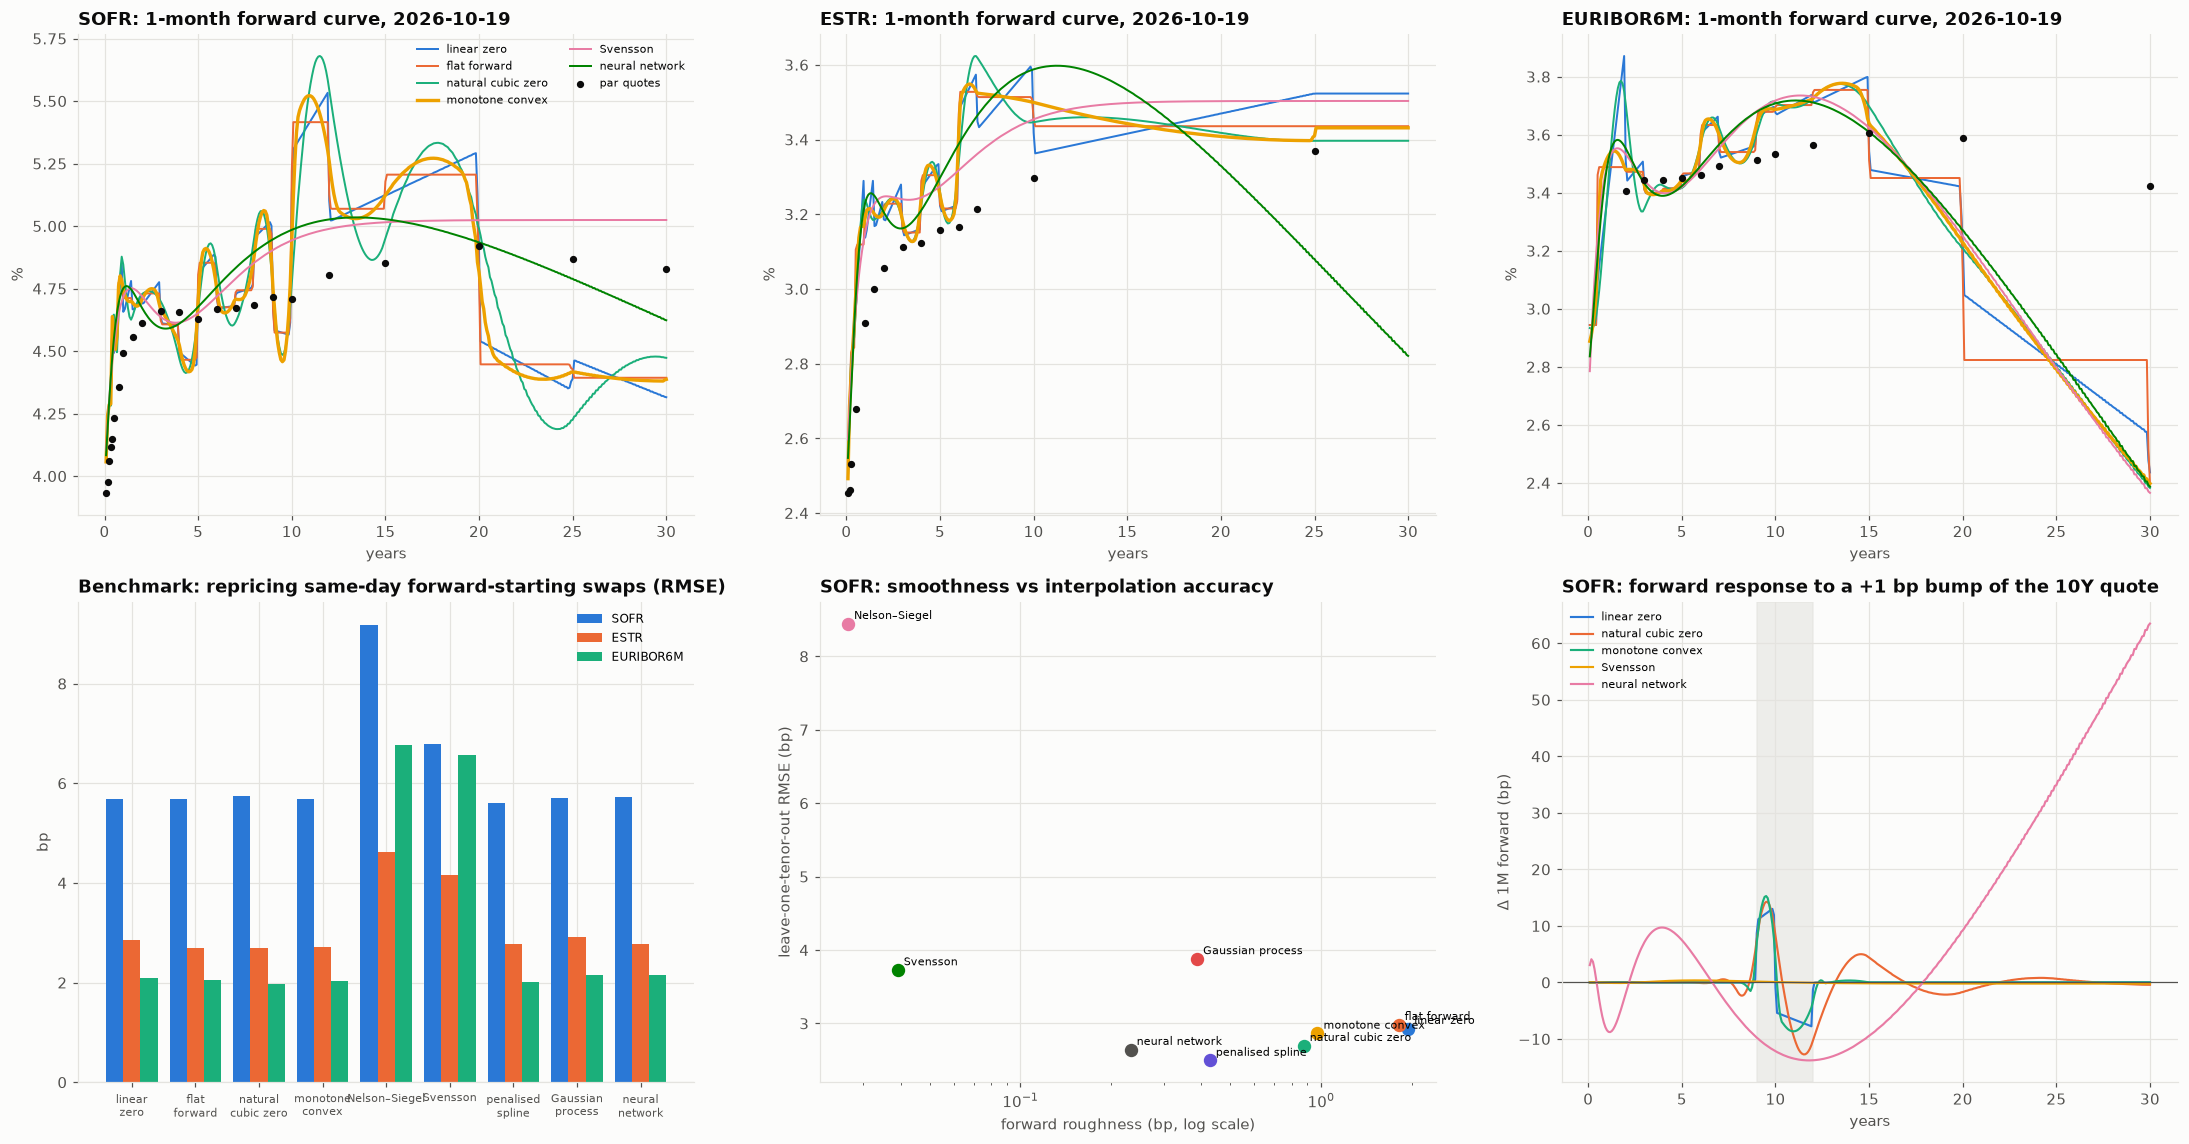

In [9]:
fig, axes = plt.subplots(2, 3, figsize=(20, 10.5))
show = [
    "linear zero",
    "flat forward",
    "natural cubic zero",
    "monotone convex",
    "Svensson",
    "neural network",
]
for ax, cv in zip(axes[0], ["SOFR", "ESTR", "EURIBOR6M"]):
    b = BOOK[(cv, day0)]
    for m, c in zip(show, PALETTE):
        ax.plot(
            FWD_T,
            FWDS[(cv, day0, m)] * 100,
            color=c,
            lw=1.3 if m != "monotone convex" else 2.2,
            label=m,
        )
    tm = b["tenor_m"][1:] / 12
    ax.scatter(
        tm[tm <= 30],
        b["rate"][1:][tm <= 30] * 100,
        color=INK,
        s=14,
        zorder=5,
        label="par quotes",
    )
    ax.set_title(f"{cv}: 1-month forward curve, {day0}")
    ax.set_xlabel("years")
    ax.set_ylabel("%")
    if cv == "SOFR":
        ax.legend(fontsize=7, ncol=2)
ax = axes[1, 0]
fs = (
    SCORE["forward-start RMSE (bp)"]
    .unstack(0)[["SOFR", "ESTR", "EURIBOR6M"]]
    .loc[METHODS]
)
xx = np.arange(len(METHODS))
for j, (cv, c) in enumerate(zip(fs.columns, PALETTE)):
    ax.bar(xx + (j - 1) * 0.27, fs[cv], 0.27, color=c, label=cv)
ax.set_xticks(xx)
ax.set_xticklabels([m.replace(" ", "\n", 1) for m in METHODS], fontsize=7)
ax.legend(fontsize=8)
ax.set_ylabel("bp")
ax.set_title("Benchmark: repricing same-day forward-starting swaps (RMSE)")
ax = axes[1, 1]
for m, c in zip(METHODS, PALETTE + [INK_2]):
    s_ = SCORE.xs("SOFR", level="curve").loc[m]
    ax.scatter(s_["roughness (bp)"], s_["LOO RMSE (bp)"], color=c, s=60)
    ax.annotate(
        m,
        (s_["roughness (bp)"], s_["LOO RMSE (bp)"]),
        fontsize=7,
        xytext=(4, 3),
        textcoords="offset points",
    )
ax.set_xscale("log")
ax.set_xlabel("forward roughness (bp, log scale)")
ax.set_ylabel("leave-one-tenor-out RMSE (bp)")
ax.set_title("SOFR: smoothness vs interpolation accuracy")
ax = axes[1, 2]
for m, c in zip(
    [
        "linear zero",
        "natural cubic zero",
        "monotone convex",
        "Svensson",
        "neural network",
    ],
    PALETTE,
):
    ax.plot(FWD_T, BUMP[("SOFR", m)], color=c, lw=1.4, label=m)
ax.axvspan(
    BOOK[("SOFR", day0)]["tenor_m"][
        list(BOOK[("SOFR", day0)]["tenor_m"]).index(120) - 1
    ]
    / 12,
    BOOK[("SOFR", day0)]["tenor_m"][
        list(BOOK[("SOFR", day0)]["tenor_m"]).index(120) + 1
    ]
    / 12,
    color=GRID,
    alpha=0.6,
)
ax.axhline(0, color=INK_2, lw=0.8)
ax.set_xlabel("years")
ax.set_ylabel("Δ 1M forward (bp)")
ax.legend(fontsize=7)
ax.set_title("SOFR: forward response to a +1 bp bump of the 10Y quote")
plt.tight_layout()
save_fig(fig, "01_forward_curve_methods")
plt.show()

In [10]:
dash = make_subplots(
    rows=1, cols=3, subplot_titles=["SOFR", "ESTR", "EURIBOR6M"]
)
for j, cv in enumerate(["SOFR", "ESTR", "EURIBOR6M"], 1):
    for m, c in zip(METHODS, PALETTE + [INK_2]):
        dash.add_trace(
            go.Scatter(
                x=FWD_T,
                y=FWDS[(cv, day0, m)] * 100,
                name=m,
                line=dict(color=c, width=1.5),
                legendgroup=m,
                showlegend=(j == 1),
            ),
            1,
            j,
        )
    b = BOOK[(cv, day0)]
    dash.add_trace(
        go.Scatter(
            x=b["tenor_m"][1:] / 12,
            y=b["rate"][1:] * 100,
            mode="markers",
            marker=dict(color="black", size=6),
            name="par quotes",
            legendgroup="q",
            showlegend=(j == 1),
        ),
        1,
        j,
    )
    dash.update_xaxes(range=[0, 30], title_text="years", row=1, col=j)
dash.update_yaxes(title_text="1M forward (%)", row=1, col=1)
dash.update_layout(
    height=560,
    width=1400,
    template="simple_white",
    title=(
        f"Forward curves by method, {day0} (click legend entries to compare)"
    ),
)
save_dashboard(dash, "dashboard")
dash.show()

Dashboard saved: outputs/dashboard.html and .png


## 10. Reading the results and limitations

**The data.**
- Ten days of reported trades give a usable curve every day for SOFR (1M–50Y), €STR and EURIBOR 6M: about 19,000 clean trades and 490 daily tenor quotes.
- The market forwards are not smooth. On 19 October 2026 SOFR rose from a 3.87% fixing to 4.7% at five years and 4.9% at twenty: the market prices hikes.
- Single-day quotes at sparsely traded tenors (12Y, 15Y, 25Y) carry a few basis points of noise. Every exact method turns that noise into forward humps, such as the 10–12Y bump of the SOFR monotone-convex curve.

**Fit and the market benchmark.**
- The four bootstraps reprice their inputs exactly (≤ 0.04 bp).
- The smoothing methods give up a little: penalised spline 0.3–0.9 bp, Gaussian process 0.3–1.1 bp, neural network 1.1–2.1 bp.
- Nelson–Siegel (4.6–6.3 bp) and Svensson (2.8–4.1 bp) cannot follow the curve's shape at all.
- **On forward-starting swaps traded the same day**, the market benchmark the curves never saw, every exact or near-exact method lands within about 0.2 bp of the others: SOFR 5.6–5.7 bp, €STR 2.7–2.9 bp, EURIBOR 2.0–2.2 bp RMSE. Most of that error is the noise of individual trades.
- Only NS and Svensson are clearly worse: SOFR 9.2 and 6.8 bp. For pricing forward-starting swaps one or two years out, the interpolation choice among sensible methods barely matters. Fitting the quotes does.

**Interpolating a missing tenor.** Leaving out one of 2–25Y in turn:
- the **penalised spline** (SOFR 2.5 bp, EURIBOR 0.7 bp) and **monotone convex** (EURIBOR 1.0 bp) interpolate best;
- the neural network is competitive (2.6 / 1.1 bp);
- linear zero and natural cubic zero do poorly on EURIBOR (5.7–5.8 bp), and NS is worst everywhere.

**Smoothness and stability.**
- Linear zero and flat forward produce the roughest forwards (1.8–2.0 bp of curvature per month on SOFR) and the most day-to-day jitter (6.5 bp).
- Monotone convex halves both. The spline, GP and network bring roughness down to 0.2–0.4 bp, and the network's jitter to 0.2 bp.

**Locality: the price of smoothness.** When the 10Y SOFR quote is bumped by 1 bp:
- linear zero, flat forward and monotone convex keep almost all of the forward response between 9Y and 12Y: 0.6% and 6% outside;
- the natural cubic spline leaks 49%;
- the global smoothers leak 80–97%. The neural network's response even *grows* to +60 bp at 30Y: it re-fits the whole curve.

A bucketed hedge computed off a global method therefore shows risk at tenors the desk never traded.

**Bottom line.** Averaging ranks across fit, the forward-start benchmark, leave-one-out, roughness, stability and locality:
1. **monotone convex** (Hagan–West) is best overall on all three curves, the reason it is the industry default for risk and P&L;
2. the **penalised spline** comes next, best for interpolation and smoothness, at the cost of locality;
3. natural cubic zero is third, then flat forward and the neural network.

NS and Svensson are useful as economic summaries (level, slope, curvature) but not as trading curves. ML curves are attractive for smooth forwards and filling gaps in sparse data, but their **non-local, unstable hedge ratios** make them unsuitable as the official risk curve without locality constraints.

**Limitations.**
- Public trade reports are not dealer quotes: notionals are capped, some trades are off-market (seasoned, MAC coupons, packages), and a daily median is noisier than a 4 pm screen close.
- The EURIBOR 6M fixing is a monthly average, and EURIBOR swaps are discounted on the same day's €STR monotone-convex curve.
- Conventions are simplified: no payment lags, OIS compounding approximated by discount-factor ratios (checked against QuantLib to 0.05 bp), and no futures or turn-of-year effects at the short end.
- Ten days is a short window for stability statistics, and the leave-one-out test uses the latest day only.
- The neural network and GP hyper-parameters (penalties, kernel width, architecture) were set once, not tuned per curve.

In [11]:
SCORE.round(4).to_csv(OUT_DIR / "method_scores_by_curve.csv")
R.round(4).to_csv(OUT_DIR / "daily_fit_results.csv", index=False)
overall.round(3).to_csv(OUT_DIR / "method_average_ranks.csv")
spot.to_csv(OUT_DIR / "spot_quotes_from_dtcc.csv", index=False)
pd.DataFrame(
    {
        f"{cv} {m}": FWDS[(cv, day0, m)]
        for cv in ["SOFR", "ESTR", "EURIBOR6M"]
        for m in METHODS
    },
    index=FWD_T,
).to_csv(OUT_DIR / "forward_curves_latest_day.csv")
print(
    "Outputs written:", ", ".join(sorted(p_.name for p_ in OUT_DIR.iterdir()))
)

Outputs written: 01_forward_curve_methods.png, daily_fit_results.csv, dashboard.html, dashboard.png, forward_curves_latest_day.csv, method_average_ranks.csv, method_scores_by_curve.csv, spot_quotes_from_dtcc.csv


## References

### Finance and regulation

- Hagan, P. S., & West, G. (2006). Interpolation methods for curve construction. *Applied Mathematical Finance, 13*(2), 89–129. https://doi.org/10.1080/13504860500396032
- Nelson, C. R., & Siegel, A. F. (1987). Parsimonious modeling of yield curves. *The Journal of Business, 60*(4), 473–489. https://doi.org/10.1086/296409
- Svensson, L. E. O. (1994). *Estimating and interpreting forward interest rates: Sweden 1992–1994* (NBER Working Paper No. 4871). National Bureau of Economic Research. https://doi.org/10.3386/w4871
- Ametrano, F. M., & Bianchetti, M. (2013). *Everything you always wanted to know about multiple interest rate curve bootstrapping but were afraid to ask*. SSRN. https://doi.org/10.2139/ssrn.2219548

### Machine learning and deep learning

- Rasmussen, C. E., & Williams, C. K. I. (2006). *Gaussian processes for machine learning*. MIT Press. https://gaussianprocess.org/gpml/
- Filipović, D., Pelger, M., & Ye, Y. (2022). *Stripping the discount curve: A robust machine learning approach*. SSRN. https://doi.org/10.2139/ssrn.4058150
- Paszke, A., Gross, S., Massa, F., Lerer, A., Bradbury, J., Chanan, G., … Chintala, S. (2019). PyTorch: An imperative style, high-performance deep learning library. *Advances in Neural Information Processing Systems, 32*. https://arxiv.org/abs/1912.01703